<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS05/datasetPBL/TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import hdbscan
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

In [2]:
# 1. Load dan gabungkan kedua dataset asli
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Ambil 6 fitur numerik dan label asli (categories)
fitur_numerik = ['rating_review', 'likes', 'latitude', 'longitude', 'rating_cafe', 'review_count']
X_scaled = StandardScaler().fit_transform(df[fitur_numerik])

le = LabelEncoder()
labels_true = le.fit_transform(df['categories'])

# Reduksi dimensi menjadi 2D menggunakan PCA untuk visualisasi
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_scaled)

In [3]:
# 2. Lakukan clustering dengan HDBSCAN
hdb = hdbscan.HDBSCAN(min_cluster_size=15).fit(X_scaled)

# 3. Laporkan jumlah cluster dan banyaknya noise
n_clusters = len(set(hdb.labels_)) - (1 if -1 in hdb.labels_ else 0)
n_noise = list(hdb.labels_).count(-1)

print(f"Jumlah cluster terbentuk : {n_clusters}")
print(f"Banyaknya data noise     : {n_noise} dari {len(df)} data ({n_noise/len(df)*100:.2f}%)")

Jumlah cluster terbentuk : 66
Banyaknya data noise     : 277 dari 2230 data (12.42%)


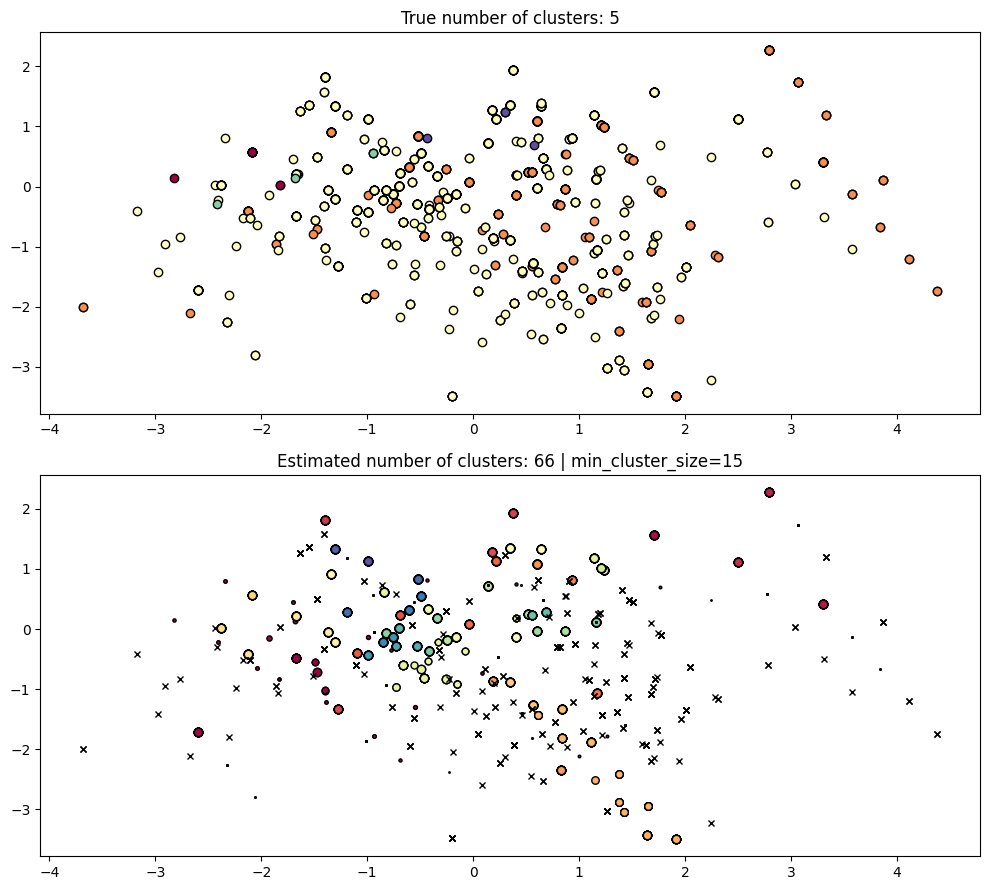

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9))

# Plot 1: Label asli (Ground Truth categories)
plot(X_pca, labels=labels_true, ground_truth=True, ax=axes[0])

# Plot 2: Hasil Clustering HDBSCAN
plot(X_pca, labels=hdb.labels_, probabilities=hdb.probabilities_,
     parameters={"min_cluster_size": 15}, ax=axes[1])

plt.show()

In [5]:
df_evaluasi = pd.DataFrame({
    'Kategori_Asli': df['categories'],
    'Cluster_HDBSCAN': hdb.labels_
})

pd.crosstab(df_evaluasi['Kategori_Asli'], df_evaluasi['Cluster_HDBSCAN'])

Cluster_HDBSCAN,-1,0,1,2,3,4,5,6,7,8,...,56,57,58,59,60,61,62,63,64,65
Kategori_Asli,,,,,,,,,,,,,,,,,,,,,
['Grosir Kopi'],2,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
['Kafe'],83,6,0,0,31,24,0,0,0,0,...,17,0,0,0,60,0,0,56,0,0
['Kedai Kopi'],187,38,30,28,0,0,25,26,27,25,...,0,26,53,29,0,33,20,0,26,32
['Toko Pakaian'],1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,3,0,0
['Toko'],4,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Hasil clustering HDBSCAN belum sepenuhnya sesuai dengan label asli categories (yang memiliki 5 kategori: Kedai Kopi, Kafe, Grosir Kopi, Toko, dan Toko Pakaian). HDBSCAN membentuk jumlah klaster yang jauh lebih banyak dibandingkan 5 kelas asli.